In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ambarish/breakhis/Folds.csv
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/README.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/count_files.sh
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/process_db_stat.py
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/fibroadenoma.stat.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/phyllodes_tumor.stat.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/tubular_adenoma.stat.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/adenosis.stat.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/README_B.txt
/kaggle/input/datasets/ambarish/breakhis/BreaKH

# BreakHis: Benign vs Malignant Classification
**Goal:** Classify breast histopathology images as benign or malignant.
**Data:** BreakHis (Spanhol et al., 2016). 7,909 H&E images, 82 patients, 4 magnifications.
**Approach:** Patient-level train/validation split, pretrained ResNet (fastai), runs tracked with MLflow.

In [3]:
%pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 73.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 68.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.5/228.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
from fastai.vision.all import *
from collections import Counter
from sklearn.metrics import roc_auc_score
import re, random, mlflow

set_seed(42, reproducible=True)          # same results every run
print('GPU:', torch.cuda.is_available())

# Find the data wherever Kaggle mounted it
PATH = next(Path('/kaggle/input').rglob('histology_slides')) / 'breast'
print(PATH)

mlflow.set_tracking_uri('sqlite:////kaggle/working/mlflow.db')
mlflow.set_experiment('breakhis')

GPU: True
/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast


2026/10/09 18:36:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/09 18:36:19 INFO mlflow.store.db.utils: Updating database tables
2026/10/09 18:36:22 INFO mlflow.tracking.fluent: Experiment with name 'breakhis' does not exist. Creating a new experiment.


<Experiment: artifact_location='/kaggle/working/mlruns/1', creation_time=1791570982177, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791570982177, lifecycle_stage='active', name='breakhis', tags={}, trace_location=None, workspace='default'>

## 1. Data Overview

In [5]:
files = get_image_files(PATH)
print(len(files), 'images')
print(files[0].name)

7909 images
SOB_B_A-14-29960CD-200-012.png


In [6]:
# code: image size check 

random.seed(42)
sizes = Counter()
for f in random.sample(list(files), 300):
    with Image.open(f) as im:
        sizes[im.size] += 1
sizes

Counter({(700, 460): 298, (700, 456): 2})

**Findings**
- 7,909 RGB PNG images (uint8), mostly 700×460; a few are 700×456 → handled by `Resize`.
- Filename format: `SOB_B_A-14-29960CD-200-012.png` (biopsy_class_type-year-patient-magnification-index).
- Some patient folders share the same number with different letter suffixes (e.g. `14-22549AB`, `14-22549CD`) → split by **patient number** to avoid leakage.

## 2. Patient IDs & train/validation split  

In [7]:
# code: patient table (200x only)

def get_patient(p): return re.search(r'-(\d+-\d+)', p.name).group(1)

MAG = '200X'
files_mag = files.filter(lambda f: f.parent.name == MAG)

df = pd.DataFrame({'path': files_mag})
df['patient'] = df.path.map(get_patient)
df['label'] = df.path.map(lambda p: 'M' if '_M_' in p.name else 'B')

print(len(df), 'images |', df.patient.nunique(), 'patients')
print('Max labels per patient:', df.groupby('patient').label.nunique().max())  # should be 1

2013 images | 70 patients
Max labels per patient: 1


In [8]:
# code: choose validation patients (~20% of each class)

rng = random.Random(42)
pats = df.groupby('patient').label.first()

valid_pats = set()
for lab in ['B', 'M']:
    ps = sorted(pats[pats == lab].index)
    valid_pats |= set(rng.sample(ps, round(len(ps) * 0.2)))

def is_valid(p): return get_patient(p) in valid_pats

df['split'] = df.path.map(lambda p: 'valid' if is_valid(p) else 'train')
pd.crosstab(df.split, df.label)

label,B,M
split,,
train,512,1111
valid,111,279


## 3. DataLoaders 

['B', 'M']


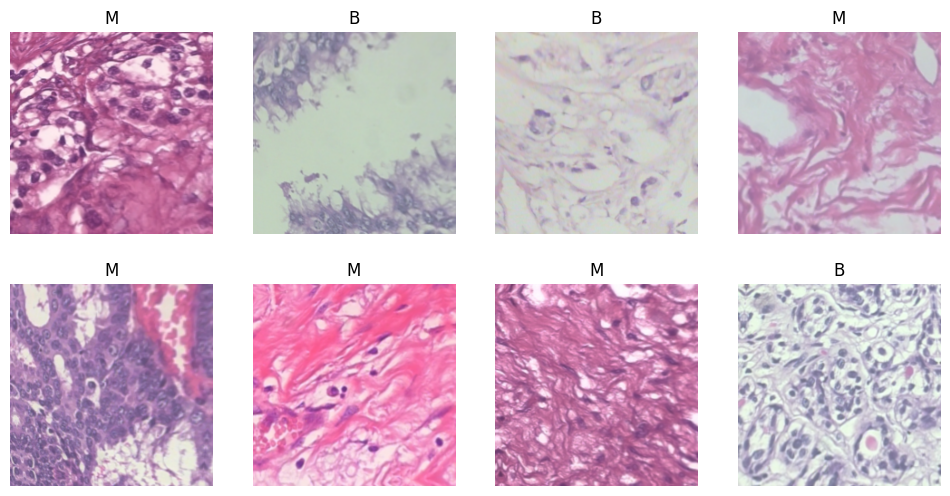

In [9]:
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_y=RegexLabeller(r'SOB_([BM])_'),
    splitter=FuncSplitter(is_valid),
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(flip_vert=True))

dls = dblock.dataloaders(files_mag, bs=32)
print(dls.vocab)
dls.show_batch(max_n=8)

## 4. Train 

In [10]:
ARCH, EPOCHS, IMG_SIZE, BS = 'resnet34', 4, 224, 32

with mlflow.start_run(run_name=f'{ARCH}_{MAG}') as run:
    mlflow.log_params({'arch': ARCH, 'epochs': EPOCHS, 'img_size': IMG_SIZE,
                       'batch_size': BS, 'magnification': MAG, 'seed': 42,
                       'n_valid_patients': len(valid_pats)})
    mlflow.log_text('\n'.join(sorted(valid_pats)), 'valid_patients.txt')

    learn = vision_learner(dls, resnet34, metrics=[error_rate, RocAucBinary()])
    learn.fine_tune(EPOCHS)

    for epoch, (trn, val, err, auc) in enumerate(learn.recorder.values):
        mlflow.log_metrics({'train_loss': trn, 'valid_loss': val,
                            'error_rate': err, 'image_auc': auc}, step=epoch)

    RUN_ID = run.info.run_id
print('Run ID:', RUN_ID)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 193MB/s] 


epoch,train_loss,valid_loss,error_rate,roc_auc_score,time
0,0.668224,0.880562,0.282051,0.740063,00:21


epoch,train_loss,valid_loss,error_rate,roc_auc_score,time
0,0.366347,0.831949,0.235897,0.769705,00:15
1,0.249508,0.834689,0.253846,0.802351,00:15
2,0.190509,1.156572,0.271795,0.747328,00:15
3,0.135110,1.085255,0.264103,0.758081,00:15


Run ID: 86f0565726ae4d48b5bdf81a1344c318


## 5. Evaluation 

In [11]:
# code: patient-level AUC 

probs, targs = learn.get_preds()
pred_df = pd.DataFrame({
    'path': dls.valid.items,
    'patient': [get_patient(p) for p in dls.valid.items],
    'label': targs.numpy(),
    'prob_malignant': probs[:, 1].numpy()})

pat_df = pred_df.groupby('patient')[['label', 'prob_malignant']].mean()
patient_auc = roc_auc_score(pat_df.label, pat_df.prob_malignant)
print('Patient-level AUC:', round(patient_auc, 3))

Patient-level AUC: 0.818


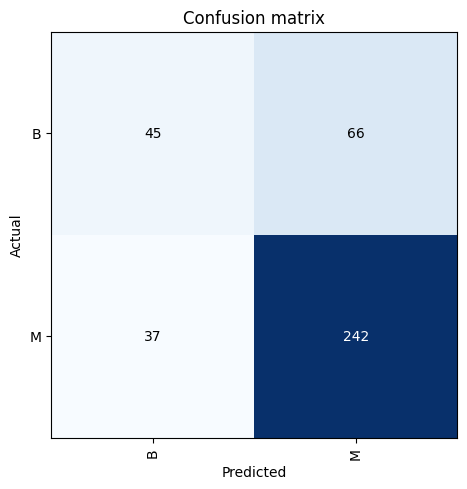

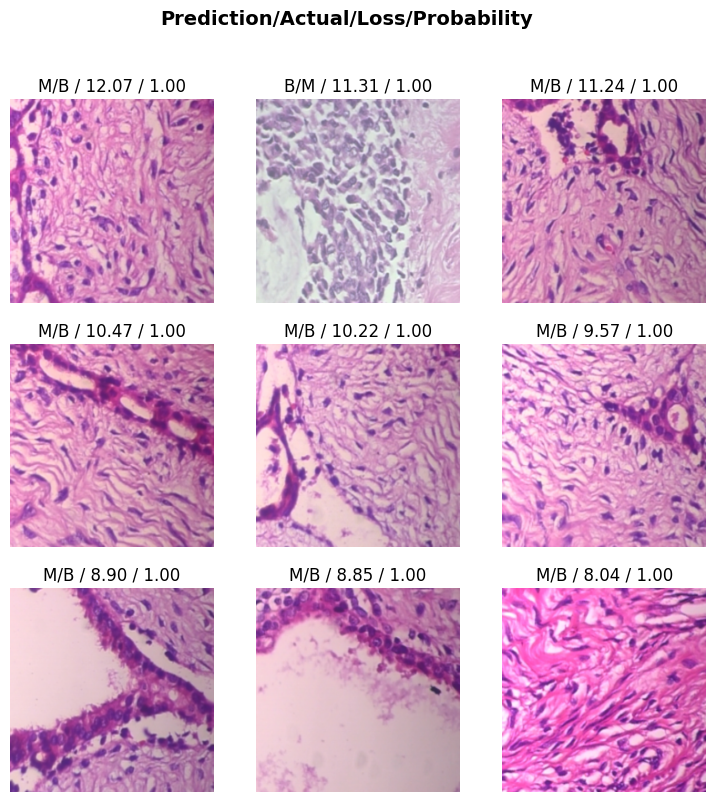

In [12]:
# code: errors, logged back to the same run 

interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()
fig_cm = plt.gcf()
interp.plot_top_losses(9, nrows=3)
fig_tl = plt.gcf()

with mlflow.start_run(run_id=RUN_ID):
    mlflow.log_metric('patient_auc', patient_auc)
    mlflow.log_figure(fig_cm, 'confusion_matrix.png')
    mlflow.log_figure(fig_tl, 'top_losses.png')
    pred_df.assign(path=pred_df.path.astype(str)).to_csv('predictions.csv', index=False)
    mlflow.log_artifact('predictions.csv')
    


In [13]:
# code: confirm what MLflow saved 

mlflow.search_runs(experiment_names=['breakhis'])[
    ['run_id', 'tags.mlflow.runName', 'metrics.image_auc', 'metrics.patient_auc', 'params.arch']]

,run_id,tags.mlflow.runName,metrics.image_auc,metrics.patient_auc,params.arch
0,86f0565726ae4d48b5bdf81a1344c318,resnet34_200X,0.758081,0.818182,resnet34


Findings (single patient split)

| Metric | Value |
|---|---|
| Image-level AUC | 0.758 (best: 0.802 at epoch 1) |
| Patient-level AUC | 0.818 |
| Error rate | 26.4% |
| Benign correctly classified | 45 / 111 (41%) |
| Malignant correctly classified | 242 / 279 (87%) |

**Key observations**
- **Benign tissue is the main failure.** Most benign images were predicted malignant, and 8 of the 9 highest-loss errors were benign images classified as malignant with ~100% confidence.
- **Overfitting after epoch 1.** Training loss kept falling (0.37 → 0.14) while validation loss rose (0.83 → 1.16).
- **Patient-level split is stricter than most published results.** Many BreakHis papers split randomly by image, which lets the same patient appear in train and test and inflates accuracy. These numbers reflect performance on unseen patients.
- **Small validation set.** Only ~5 benign validation patients, so results from a single split are noisy.

**Next steps**
1. Error analysis by tumor type (Section 6).
2. Train for fewer epochs (1–2).
3. Weight the loss to address class imbalance (fewer benign images).
4. Patient-level 5-fold cross-validation for a more reliable estimate.
5. Export per-image features for traceability.
6. Compare magnifications (40X, 100X, 400X).

## 6. Error analysis by tumor type 

In [14]:
pred_df['tumor_type'] = pred_df.path.map(lambda p: p.name.split('_')[2].split('-')[0])
pred_df['pred'] = (pred_df.prob_malignant > 0.5).astype(int)
pred_df['correct'] = pred_df.pred == pred_df.label

pred_df.groupby(['label', 'tumor_type']).correct.agg(['mean', 'count'])


mean  count
label tumor_type                 
0     F           0.000000     32
      TA          0.569620     79
1     DC          0.838384    198
      LC          1.000000     28
      MC          0.905660     53

- **Errors concentrate in fibroadenoma (0% correct, 32 images)** and tubular adenoma (57%); malignant types range 84–100%.
- **Validation set is missing tumor types** (no adenosis, phyllodes, or papillary carcinoma), a side effect of the small patient count. Next split should be stratified by tumor type.

In [15]:
# code: Is it the tumor type, or one patient? 

pred_df.groupby(['tumor_type', 'patient']).correct.agg(['mean', 'count'])

mean  count
tumor_type patient                  
DC         14-12312  0.971429     35
           14-14926  1.000000     18
           14-14946  0.588235     34
           14-15572  1.000000     19
           14-16601  1.000000     10
           14-20629  1.000000     32
           14-3909   0.413793     29
           14-5694   1.000000     21
F          14-25197  0.000000     32
LC         14-12204  1.000000     28
MC         14-12773  0.952381     21
           14-18842  0.875000     32
TA         14-13200  0.904762     21
           14-16184  0.448276     58

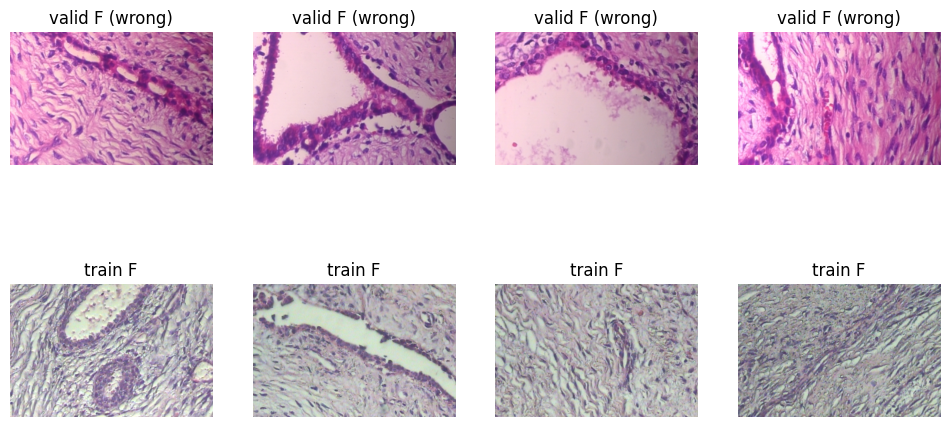

In [16]:
# what is different about patient 14-25197?

bad = [p for p in files_mag if get_patient(p) == '14-25197'][:4]
good = [p for p in files_mag if '_F-' in p.name and get_patient(p) not in valid_pats][:4]

show_images([PILImage.create(p) for p in bad + good], nrows=2,
            titles=['valid F (wrong)']*4 + ['train F']*4)

- **Errors are patient-driven.** All fibroadenoma errors come from a single patient (14-25197, 0/32); TA accuracy ranges from 45% to 90% across its two patients; two DC patients fall below 60%.
- **Benign evaluation rests on only 3 patients**, so a single difficult patient strongly affects the metrics → patient-level cross-validation is needed.

## 7. Patient-level cross validation 

In [18]:
from sklearn.model_selection import StratifiedGroupKFold

# Tumor type from the filename (same logic as Section 6)
df['tumor_type'] = df.path.map(lambda p: p.name.split('_')[2].split('-')[0])

EPOCHS, N_FOLDS = 2, 5
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
img_aucs, pat_aucs, oof = [], [], []

with mlflow.start_run(run_name=f'cv{N_FOLDS}_{ARCH}_{MAG}'):
    mlflow.log_params({'arch': ARCH, 'epochs': EPOCHS, 'img_size': IMG_SIZE, 'batch_size': BS,
                       'magnification': MAG, 'n_folds': N_FOLDS, 'seed': 42,
                       'split': 'StratifiedGroupKFold(y=tumor_type, groups=patient)'})

    for fold, (_, va_idx) in enumerate(sgkf.split(df, df.tumor_type, df.patient)):
        va_pats = set(df.patient.iloc[va_idx])

        # DataBlock (same as Cell 12, but this fold's patients are held out)
        fold_block = DataBlock(
            blocks=(ImageBlock, CategoryBlock),
            get_y=RegexLabeller(r'SOB_([BM])_'),
            splitter=FuncSplitter(lambda p: get_patient(p) in va_pats),
            item_tfms=Resize(IMG_SIZE),
            batch_tfms=aug_transforms(flip_vert=True))
        fdls = fold_block.dataloaders(files_mag, bs=BS)

        # Fresh model each fold (same as Cell 14)
        flearn = vision_learner(fdls, resnet34, metrics=[error_rate, RocAucBinary()])
        with flearn.no_bar(), flearn.no_logging():
            flearn.fine_tune(EPOCHS)

        # Predictions on held-out patients (same as Cell 16)
        probs, targs = flearn.get_preds()
        fold_df = pd.DataFrame({
            'path': [str(p) for p in fdls.valid.items],
            'patient': [get_patient(p) for p in fdls.valid.items],
            'label': targs.numpy(),
            'prob_malignant': probs[:, 1].numpy(),
            'fold': fold})

        img_auc = roc_auc_score(fold_df.label, fold_df.prob_malignant)
        pat = fold_df.groupby('patient')[['label', 'prob_malignant']].mean()
        pat_auc = roc_auc_score(pat.label, pat.prob_malignant)

        img_aucs.append(img_auc); pat_aucs.append(pat_auc); oof.append(fold_df)
        mlflow.log_metrics({'fold_image_auc': img_auc, 'fold_patient_auc': pat_auc}, step=fold)
        print(f'Fold {fold}: image AUC {img_auc:.3f} | patient AUC {pat_auc:.3f} | {len(va_pats)} valid patients')

    # Combine all folds: every image predicted by a model that never saw its patient
    oof = pd.concat(oof)
    pat_all = oof.groupby('patient')[['label', 'prob_malignant']].mean()
    oof_pat_auc = roc_auc_score(pat_all.label, pat_all.prob_malignant)

    mlflow.log_metrics({'cv_image_auc_mean': np.mean(img_aucs), 'cv_image_auc_std': np.std(img_aucs),
                        'cv_patient_auc_mean': np.mean(pat_aucs), 'cv_patient_auc_std': np.std(pat_aucs),
                        'oof_patient_auc': oof_pat_auc})
    oof.to_csv('oof_predictions.csv', index=False)
    mlflow.log_artifact('oof_predictions.csv')

print(f'\nImage AUC:   {np.mean(img_aucs):.3f} ± {np.std(img_aucs):.3f}')
print(f'Patient AUC: {np.mean(pat_aucs):.3f} ± {np.std(pat_aucs):.3f}')
print(f'Out-of-fold patient AUC (all patients): {oof_pat_auc:.3f}')

Fold 0: image AUC 0.992 | patient AUC 1.000 | 15 valid patients


Fold 1: image AUC 0.785 | patient AUC 1.000 | 17 valid patients


Fold 2: image AUC 0.916 | patient AUC 0.972 | 13 valid patients


Fold 3: image AUC 0.952 | patient AUC 1.000 | 12 valid patients


Fold 4: image AUC 0.829 | patient AUC 0.825 | 13 valid patients

Image AUC:   0.895 ± 0.077
Patient AUC: 0.959 ± 0.068
Out-of-fold patient AUC (all patients): 0.944


**Findings**
- 5-fold patient-level CV (stratified by tumor type): image AUC 0.895 ± 0.077, patient AUC 0.959 ± 0.068; out-of-fold patient AUC across all 70 patients = 0.944.
- High variance across folds (image AUC 0.79–0.99) → the earlier single split was unrepresentative.
- Epochs also changed (4 → 2), so the improvement can't be attributed to the split alone; see follow-up run.
- Patient IDs merged by number give 70 patients (not 82).

In [19]:
# Out-of-fold error analysis: every patient tested once
oof['tumor_type'] = oof.path.map(lambda p: Path(p).name.split('_')[2].split('-')[0])
oof['pred'] = (oof.prob_malignant > 0.5).astype(int)
oof['correct'] = oof.pred == oof.label

by_type = oof.groupby(['label', 'tumor_type']).agg(
    accuracy=('correct', 'mean'),
    images=('correct', 'count'),
    patients=('patient', 'nunique'))
by_type

accuracy  images  patients
label tumor_type                            
0     A           0.585586     111         2
      F           0.742424     264         7
      PT          0.740741     108         3
      TA          0.807143     140         6
1     DC          0.931920     896        38
      LC          0.889571     163         4
      MC          0.683673     196         7
      PC          0.770370     135         6

In [20]:
by_patient = oof.groupby(['tumor_type', 'patient']).correct.agg(['mean', 'count'])
by_patient.sort_values('mean').head(10)

mean  count
tumor_type patient                  
F          14-29960  0.000000     18
           14-25197  0.031250     32
MC         14-10147  0.272727     22
PC         14-15687  0.285714     14
DC         14-14946  0.470588     34
MC         14-12773  0.476190     21
PT         14-21998  0.500000     52
MC         14-19979  0.513514     37
A          14-22549  0.515789     95
PC         14-9146   0.523810     21

In [21]:
CV_RUN_ID = mlflow.search_runs(experiment_names=['breakhis'],
                               filter_string="tags.mlflow.runName = 'cv5_resnet34_200X'").run_id.iloc[0]

with mlflow.start_run(run_id=CV_RUN_ID):
    mlflow.log_text(by_type.to_string(), 'oof_by_tumor_type.txt')
    mlflow.log_text(by_patient.to_string(), 'oof_by_patient.txt')
    

**Findings (out-of-fold)**
- Ductal carcinoma (38 patients) is classified best (93%); rarer types are weaker: mucinous 68%, adenosis 59%, papillary 77%.
- Fibroadenoma errors come from 2 of 7 patients (14-29960, 14-25197, both ~0%); the rest are classified well.
- Hardest patients include both benign and malignant cases → performance is driven by patient-level variation and tumor-type imbalance.
- A few patients carry two tumor types, so per-type patient counts sum to 73.

## 8. Epochs comparison (2 vs 4)
The first CV run changed two things at once (split method and 4 → 2 epochs). Re-running CV with 4 epochs isolates the effect of training length.

In [22]:
def run_cv(epochs, mag=MAG, n_folds=5, arch=resnet34):
    """Patient-level, tumor-type-stratified CV. Logs everything to one MLflow run."""
    # Data for this magnification (same logic as Cell 9)
    files_m = files.filter(lambda f: f.parent.name == mag)
    df_m = pd.DataFrame({'path': files_m})
    df_m['patient'] = df_m.path.map(get_patient)
    df_m['tumor_type'] = df_m.path.map(lambda p: p.name.split('_')[2].split('-')[0])

    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=42)
    img_aucs, pat_aucs, oof = [], [], []
    run_name = f'cv{n_folds}_{arch.__name__}_{mag}_ep{epochs}'

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({'arch': arch.__name__, 'epochs': epochs, 'img_size': IMG_SIZE,
                           'batch_size': BS, 'magnification': mag, 'n_folds': n_folds, 'seed': 42,
                           'split': 'StratifiedGroupKFold(y=tumor_type, groups=patient)'})

        for fold, (_, va_idx) in enumerate(sgkf.split(df_m, df_m.tumor_type, df_m.patient)):
            va_pats = set(df_m.patient.iloc[va_idx])

            fold_block = DataBlock(
                blocks=(ImageBlock, CategoryBlock),
                get_y=RegexLabeller(r'SOB_([BM])_'),
                splitter=FuncSplitter(lambda p: get_patient(p) in va_pats),
                item_tfms=Resize(IMG_SIZE),
                batch_tfms=aug_transforms(flip_vert=True))
            fdls = fold_block.dataloaders(files_m, bs=BS)

            flearn = vision_learner(fdls, arch, metrics=[error_rate, RocAucBinary()])
            with flearn.no_bar(), flearn.no_logging():
                flearn.fine_tune(epochs)

            probs, targs = flearn.get_preds()
            fold_df = pd.DataFrame({
                'path': [str(p) for p in fdls.valid.items],
                'patient': [get_patient(p) for p in fdls.valid.items],
                'tumor_type': [p.name.split('_')[2].split('-')[0] for p in fdls.valid.items],
                'label': targs.numpy(),
                'prob_malignant': probs[:, 1].numpy(),
                'fold': fold})

            img_auc = roc_auc_score(fold_df.label, fold_df.prob_malignant)
            pat = fold_df.groupby('patient')[['label', 'prob_malignant']].mean()
            pat_auc = roc_auc_score(pat.label, pat.prob_malignant)

            img_aucs.append(img_auc); pat_aucs.append(pat_auc); oof.append(fold_df)
            mlflow.log_metrics({'fold_image_auc': img_auc, 'fold_patient_auc': pat_auc}, step=fold)
            print(f'[{run_name}] Fold {fold}: image AUC {img_auc:.3f} | patient AUC {pat_auc:.3f}')

        oof = pd.concat(oof)
        pat_all = oof.groupby('patient')[['label', 'prob_malignant']].mean()
        oof_pat_auc = roc_auc_score(pat_all.label, pat_all.prob_malignant)

        summary = {'cv_image_auc_mean': np.mean(img_aucs), 'cv_image_auc_std': np.std(img_aucs),
                   'cv_patient_auc_mean': np.mean(pat_aucs), 'cv_patient_auc_std': np.std(pat_aucs),
                   'oof_patient_auc': oof_pat_auc}
        mlflow.log_metrics(summary)
        oof.to_csv(f'oof_{run_name}.csv', index=False)
        mlflow.log_artifact(f'oof_{run_name}.csv')

    summary['run_id'] = run.info.run_id
    return oof, summary

In [23]:
oof_ep4, summary_ep4 = run_cv(epochs=4)

[cv5_resnet34_200X_ep4] Fold 0: image AUC 0.985 | patient AUC 1.000


[cv5_resnet34_200X_ep4] Fold 1: image AUC 0.796 | patient AUC 0.967


[cv5_resnet34_200X_ep4] Fold 2: image AUC 0.921 | patient AUC 0.944


[cv5_resnet34_200X_ep4] Fold 3: image AUC 0.953 | patient AUC 1.000


[cv5_resnet34_200X_ep4] Fold 4: image AUC 0.819 | patient AUC 0.900


In [24]:
summary_ep2 = {'cv_image_auc_mean': np.mean(img_aucs), 'cv_image_auc_std': np.std(img_aucs),
               'cv_patient_auc_mean': np.mean(pat_aucs), 'cv_patient_auc_std': np.std(pat_aucs),
               'oof_patient_auc': oof_pat_auc, 'run_id': CV_RUN_ID}

comparison = pd.DataFrame([summary_ep2, summary_ep4], index=['2 epochs', '4 epochs'])
comparison.round(3)

,cv_image_auc_mean,cv_image_auc_std,cv_patient_auc_mean,cv_patient_auc_std,oof_patient_auc,run_id
2 epochs,0.895,0.077,0.959,0.068,0.944,3c1a44dfee1b4275a56437c500ec7e2f
4 epochs,0.895,0.074,0.962,0.038,0.954,6437d387239c4126af445ab0f47a9634


**Findings**
- 2 vs 4 epochs give nearly identical results (image AUC 0.895 both; OOF patient AUC 0.944 vs 0.954), within fold-to-fold variation.
- → The improvement over the first single split (image AUC 0.76) comes from the evaluation (CV across all patients), not training length; the first split contained unusually hard patients.
- Rising validation loss with stable AUC suggests the model became more overconfident, not worse at ranking.
- **Final configuration: ResNet34, 200X, 4 epochs** (best OOF patient AUC, lowest variance across folds).

## 9. Feature export (traceability)
Train the final model (ResNet34, 200X, 4 epochs) and export each image's 512-dimensional feature vector with its image ID, patient ID, tumor type, label, predictions, and MLflow run ID. Any prediction can be traced back to the exact run and features that produced it.

In [25]:
FINAL_EPOCHS = 4
files_m = files.filter(lambda f: f.parent.name == MAG)

final_block = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_y=RegexLabeller(r'SOB_([BM])_'),
    splitter=RandomSplitter(valid_pct=0.1, seed=42),   # only for monitoring training
    item_tfms=Resize(IMG_SIZE),
    batch_tfms=aug_transforms(flip_vert=True))
final_dls = final_block.dataloaders(files_m, bs=BS)

final_run = mlflow.start_run(run_name=f'final_{ARCH}_{MAG}_ep{FINAL_EPOCHS}')
mlflow.log_params({'arch': ARCH, 'epochs': FINAL_EPOCHS, 'img_size': IMG_SIZE, 'batch_size': BS,
                   'magnification': MAG, 'seed': 42, 'purpose': 'final model + feature export',
                   'cv_reference_run': summary_ep4['run_id']})

final_learn = vision_learner(final_dls, resnet34, metrics=error_rate)
final_learn.fine_tune(FINAL_EPOCHS)
FINAL_RUN_ID = final_run.info.run_id

epoch,train_loss,valid_loss,error_rate,time
0,0.716439,0.329280,0.089552,00:15


epoch,train_loss,valid_loss,error_rate,time
0,0.405169,0.206499,0.079602,00:16
1,0.310714,0.124769,0.054726,00:16
2,0.217218,0.085561,0.029851,00:16
3,0.160508,0.068035,0.034826,00:16


In [26]:
# Feature extractor: the whole model except the final B/M layer → 512 numbers per image
feat_model = nn.Sequential(final_learn.model[0], final_learn.model[1][:-1]).eval()

test_dl = final_dls.test_dl(files_m)      # same resizing, no random augmentation, same order
feats = []
with torch.no_grad():
    for (xb,) in test_dl:
        feats.append(feat_model(xb).cpu())
feats = torch.cat(feats).numpy()

probs, _ = final_learn.get_preds(dl=test_dl)

export = pd.DataFrame({
    'image_id': [p.name for p in files_m],
    'path': [str(p) for p in files_m],
    'patient': [get_patient(p) for p in files_m],
    'tumor_type': [p.name.split('_')[2].split('-')[0] for p in files_m],
    'label': [1 if '_M_' in p.name else 0 for p in files_m],
    'magnification': MAG,
    'run_id': FINAL_RUN_ID,
    'prob_malignant_final': probs[:, 1].numpy()})

# Attach the honest out-of-fold prediction from the CV run
export = export.merge(oof_ep4[['path', 'prob_malignant']].rename(
    columns={'prob_malignant': 'prob_malignant_oof'}), on='path', how='left')

feat_cols = pd.DataFrame(feats, columns=[f'feat_{i}' for i in range(feats.shape[1])])
export = pd.concat([export, feat_cols], axis=1)

print(export.shape)
export.iloc[:3, :10]

(2013, 521)


,image_id,path,patient,tumor_type,label,magnification,run_id,prob_malignant_final,prob_malignant_oof,feat_0
0,SOB_B_A-14-29960CD-200-012.png,/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-29960CD/200X/SOB_B_A-14-29960CD-200-012.png,14-29960,A,0,200X,15767fcd501f45f68bc7bc169e911a16,3.775839e-06,0.000002,-0.581352
1,SOB_B_A-14-29960CD-200-009.png,/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-29960CD/200X/SOB_B_A-14-29960CD-200-009.png,14-29960,A,0,200X,15767fcd501f45f68bc7bc169e911a16,4.282301e-07,0.000003,-0.082400
2,SOB_B_A-14-29960CD-200-006.png,/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-29960CD/200X/SOB_B_A-14-29960CD-200-006.png,14-29960,A,0,200X,15767fcd501f45f68bc7bc169e911a16,5.983948e-03,0.009104,0.363602


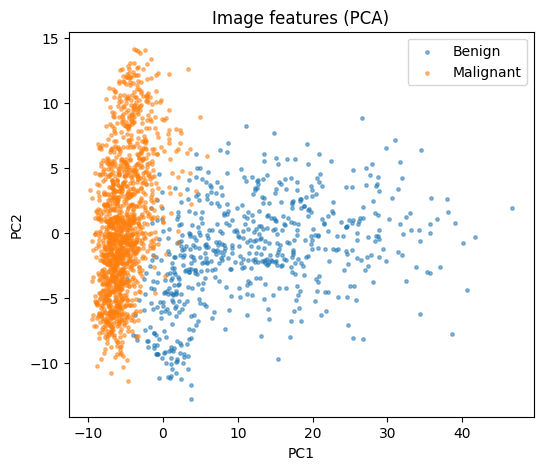

In [27]:
from sklearn.decomposition import PCA

export.to_parquet('features_200X.parquet', index=False)
mlflow.log_artifact('features_200X.parquet')
mlflow.log_metric('n_images_exported', len(export))

# Quick look: do the features separate benign from malignant?
pcs = PCA(n_components=2).fit_transform(feats)
fig, ax = plt.subplots(figsize=(6, 5))
for lab, name in [(0, 'Benign'), (1, 'Malignant')]:
    m = export.label == lab
    ax.scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.5, label=name)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(); ax.set_title('Image features (PCA)')
mlflow.log_figure(fig, 'features_pca.png')

final_learn.export('final_model.pkl')
mlflow.log_artifact('final_model.pkl')
mlflow.end_run()

**Findings**
- Malignant images form a tight cluster (PC1 ≈ −5), while benign images spread widely along PC1 (≈ 0 to 45) → benign tissue is far more heterogeneous in the model's feature space.
- The two classes overlap mainly near PC1 ≈ 0, where most errors are expected.
- Caveat: features come from the final model, which was trained on these images, so the separation shown here is optimistic.

## 10. Traceability demo
Trace the most confident misclassification back to its source: image, patient, tumor type, predictions, run ID, and the most similar images (from other patients) in feature space.

image_id                    SOB_M_PC-14-9146-200-011.png
patient                                          14-9146
tumor_type                                            PC
label                                                  1
prob_malignant_oof                                   0.0
prob_malignant_final                            0.472878
run_id                  15767fcd501f45f68bc7bc169e911a16

Misclassified images: 352 of 2013


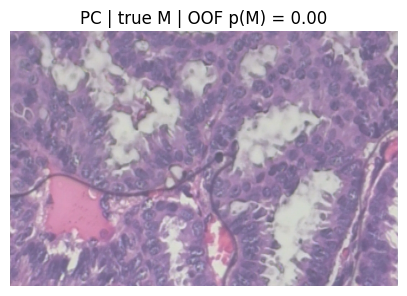

In [31]:
# find and inspect the case 

export['pred_oof'] = (export.prob_malignant_oof > 0.5).astype(int)
wrong = export[export.pred_oof != export.label]
case = wrong.loc[(wrong.prob_malignant_oof - 0.5).abs().idxmax()]   # most confident mistake

info_cols = ['image_id', 'patient', 'tumor_type', 'label',
             'prob_malignant_oof', 'prob_malignant_final', 'run_id']
print(case[info_cols].to_string())
print(f'\nMisclassified images: {len(wrong)} of {len(export)}')

show_image(PILImage.create(case.path), figsize=(5, 4),
           title=f"{case.tumor_type} | true {'M' if case.label else 'B'} | OOF p(M) = {case.prob_malignant_oof:.2f}");

,image_id,patient,tumor_type,label,similarity
486,SOB_B_F-14-21998CD-200-034.png,14-21998,F,0,0.432
460,SOB_B_F-14-21998CD-200-033.png,14-21998,F,0,0.402
1946,SOB_M_PC-14-19440-200-013.png,14-19440,PC,1,0.391
431,SOB_B_F-14-21998EF-200-007.png,14-21998,F,0,0.385
1937,SOB_M_PC-14-19440-200-023.png,14-19440,PC,1,0.382
193,SOB_B_PT-14-22704-200-024.png,14-22704,PT,0,0.371


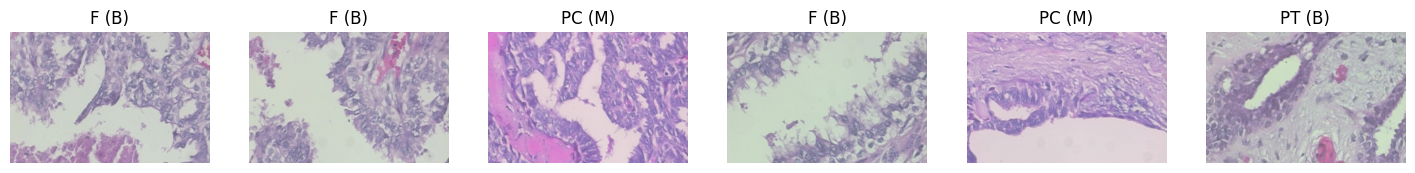

In [29]:
# what does the model think it looks like? 

F = export.filter(like='feat_').values
F = F / np.linalg.norm(F, axis=1, keepdims=True)    # normalize → dot product = cosine similarity

sims = F @ F[case.name]
sims[(export.patient == case.patient).values] = -np.inf   # ignore the same patient's images
nn_idx = np.argsort(-sims)[:6]

neighbors = export.iloc[nn_idx][['image_id', 'patient', 'tumor_type', 'label']].assign(
    similarity=sims[nn_idx].round(3))
display(neighbors)

show_images([PILImage.create(p) for p in export.iloc[nn_idx].path], nrows=1, figsize=(18, 3),
            titles=[f"{t} ({'M' if l else 'B'})" for t, l in zip(neighbors.tumor_type, neighbors.label)])

In [30]:
# log the trace to MLflow 

report = case[info_cols].to_string() + '\n\nNearest neighbors (other patients):\n' + neighbors.to_string()
with mlflow.start_run(run_id=FINAL_RUN_ID):
    mlflow.log_text(report, f"trace_{case.image_id.replace('.png', '')}.txt")

**Findings**
- Out-of-fold, 352 of 2,013 images (17.5%) are misclassified.
- **Most confident error:** `SOB_M_PC-14-9146-200-011.png`, a papillary carcinoma (malignant) from patient 14-9146. The CV model that never saw this patient predicted p(malignant) = 0.00; even the final model, trained on it, is unsure (0.47). Patient 14-9146 was already among the hardest patients (52% accuracy).
- **Nearest neighbors from other patients:** 4 of 6 are benign (3 fibroadenoma from patient 14-21998, 1 phyllodes tumor); the other 2 are papillary carcinomas from patient 14-19440.
- **Interpretation:** the glandular, papillary architecture of this carcinoma resembles the duct-rich structure of fibroepithelial benign lesions (fibroadenoma, phyllodes) in feature space. Papillary carcinoma is also rare in the data (6 patients), so the model has seen few examples of it.
- This trace (image → patient → predictions → run ID → similar cases) is logged to the final MLflow run as an artifact.

## 11. Results and conclusions

**Data:** BreakHis, 200X magnification: 2,013 images from 70 patients (patient IDs grouped by number, so slides from the same patient stay together).

**Final configuration:** ResNet34 (ImageNet-pretrained, fastai), 224×224, 4 epochs, flips/rotation/zoom augmentation.

### Performance (5-fold patient-level CV, stratified by tumor type)
| Metric | Value |
|---|---|
| Image-level AUC | 0.895 ± 0.074 |
| Patient-level AUC | 0.962 ± 0.038 |
| **Out-of-fold patient AUC (all 70 patients)** | **0.954** |
| Out-of-fold misclassified images | 352 / 2,013 (17.5%) |

MLflow runs: CV `0990812d…` · final model + features `15767fcd…`

### Key findings
1. **Evaluation design mattered more than training length.** A single patient split gave image AUC 0.76; cross-validation across all patients gave 0.90. Changing 2 → 4 epochs had almost no effect. The first split happened to contain unusually hard patients.
2. **Errors are driven by patients and tumor-type imbalance.** Ductal carcinoma (38 patients) is classified best (93%); rarer types are weaker (mucinous 68%, adenosis 59%). Fibroadenoma errors come from 2 of its 7 patients.
3. **Benign tissue is more heterogeneous** than malignant tissue in the model's feature space (PCA).
4. **Traceability:** every image is linked to its patient, predictions, 512-dim features, and MLflow run. The most confident error, a papillary carcinoma, sits closest to benign fibroadenoma and phyllodes images in feature space, which suggests the model confuses glandular/papillary architecture with fibroepithelial lesions.

### Limitations
- One magnification (200X), one dataset from a single lab: no external validation.
- Small cohort: 70 patients, only ~18 benign; per-fold patient AUCs are coarse.
- No stain normalization; decision threshold fixed at 0.5.
- Tumor-type results come from the 2-epoch CV run.

### Next steps
- Compare magnifications (40X, 100X, 400X) with `run_cv`.
- Stain normalization and tumor-type–aware loss weighting.
- Validate on an external histopathology dataset.
- Apply the same pipeline (patient-level CV, MLflow, feature export) to mammograms (CBIS-DDSM).